In [1]:
import numpy as np
import mindspore as ms
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer
import matplotlib.pyplot as plt


from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

import numpy as np
import mindspore as ms
from mindquantum import *
import matplotlib.pyplot as plt
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer


from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator
import numpy
import scipy
import scipy.linalg

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer


import itertools
from collections import OrderedDict

import numpy as np

from mindquantum.core.circuit import Circuit, decompose_single_term_time_evolution
from mindquantum.core.operators import FermionOperator, down_index, up_index
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package

from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import random
import matplotlib.pyplot as plt

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):  # pylint: disable=too-many-locals,too-many-statements
    """
    Generate a uccsd quantum circuit.

    Args:
        mol (molecular): A hdf5 molecular file generated by HiQ Fermion.
        threshold (float, optional): A threshold of parameters. If the absolute value of parameter is
            lower than the threshold, than we will not update it in VQE
            algorithm. Default: ``0``.
    """
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    # Unpack amplitudes
    n_single_amplitudes = n_occupied * n_virtual
    # Generate excitations
    spin_index_functions = [up_index, down_index]
    # Generate all spin-conserving single and double excitations derived
    # from one spatial occupied-virtual pair
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):  # pylint: disable=invalid-name
        # Get indices of spatial orbitals
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            # Get indices of spin orbitals
            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            # Generate single excitations
            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            # Generate double excitation
            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])
    out.extend(out_tmp)
    out_tmp = []
    # Generate all spin-conserving double excitations derived
    # from two spatial occupied-virtual pairs
    for i, ((p, q), (r, s)) in enumerate(  # pylint: disable=invalid-name
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):

        # Get indices of spatial orbitals
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        # Generate double excitations
        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            # Get indices of spin orbitals
            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)
            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])
    return out, params

def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    """
    Generate a uccsd quantum circuit based on a molecular data generated by Openfermion.

    Args:
        molecular (Union[str, MolecularData]): the name of the molecular data file,
            or openfermion MolecularData.
        threshold (float): the threshold to filter out the uccsd amplitude. We only keep the
            excitation operator with absolute value of amplitude greater than `threshold`, so
            that if `threshold=0`, we only keep excitation operator with non zero amplitude. Default: ``0``.

    Returns:
        - **uccsd_circuit** (Circuit), the ansatz circuit generated by uccsd method.
        - **initial_amplitudes** (numpy.ndarray), the initial parameter values of uccsd circuit.
        - **parameters_name** (list[str]), the name of initial parameters.
        - **qubit_hamiltonian** (QubitOperator), the hamiltonian of the molecule.
        - **n_qubits** (int), the number of qubits in simulation.
        - **n_electrons** (int), the number of electrons of the molecule.
    """
    try:
        # pylint: disable=import-outside-toplevel
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(mol, threshold, n_qubits=2*(active_space_stop-active_space_start), n_electrons=mol.n_electrons-2*active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(list(range(active_space_start)), active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return uccsd_circuit, initial_amplitudes, parameters_name, qubit_hamiltonian, 2*(active_space_stop-active_space_start), mol.n_electrons-2*active_space_start

def get_mol(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    # 设置基组和自旋多重性
    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1  # 假设为闭壳层单重态

    # 创建分子对象
    molecule = MolecularData(
        geometry,
        basis,
        multiplicity,
        description=description
    )

    # molecule = run_pyscf(
    #     molecule,
    #     run_scf=1,
    #     run_ccsd=1,
    #     #run_fci=1
    # )

    # 显式指定文件名
    #molecule.filename = "./test_h2.hdf5"
    # molecule.save()
    # molecule_file = molecule.filename
    # print(molecule_file.split('/')[-1])

    # 运行或加载计算
    try:
        molecule.load()
    except:
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()
        molecule_file = molecule.filename
        print(molecule_file.split('/')[-1])

    # 打印能量信息
    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
   # print(f'{description} - FCI energy: {molecule.fic_energy} Hartree.')

    
    return molecule
    


[WARNING] ME(1212056:137961215152128,MainProcess):2026-10-08-11:33:18.350.00 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


[['Zr', [np.float64(1.2397611467218508), np.float64(0.22042881), np.float64(1.102028681533527)]], ['O', [np.float64(4.657048362037544), np.float64(4.36031376), np.float64(0.8211243583071115)]], ['O', [np.float64(1.4584165528787967), np.float64(3.8836934000000003), np.float64(5.145324267709785)]]]
Monoclinic ZrO2 - Hartree-Fock energy: -608.1196082141597 Hartree.
Monoclinic ZrO2 - CCSD energy: -608.3663660904948 Hartree.
Step 0: Energy = -607.60034
Step 10: Energy = -608.11096
Step 20: Energy = -608.11816
Step 30: Energy = -608.11926
Step 40: Energy = -608.1195
Step 50: Energy = -608.11957
Step 60: Energy = -608.11957
Step 70: Energy = -608.1196
Step 80: Energy = -608.1196
Step 90: Energy = -608.1196


/tmp/ipykernel_769280/2934533592.py:78: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


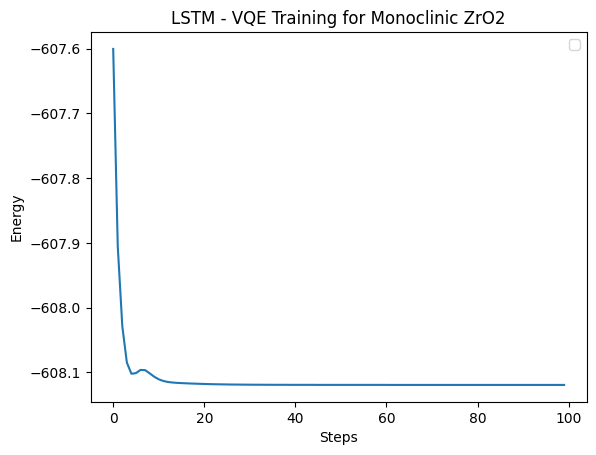

Estimated ground state energy of Monoclinic ZrO2: -608.11962890625


In [7]:
ZrO2d=get_mol(1)
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=27, active_space_stop=33)

hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
ham = Hamiltonian(hamiltonian_QubitOp)      # 生成哈密顿量
#init_state_circ = UN(H, g_6.nodes)         # 生成均匀叠加态，即对所有量子比特作用H门
ansatz = ansatz_circuit   # 生成拟设线路
circ = hartreefock_wfn_circuit + ansatz_circuit.as_encoder()       # 将初始化线路与拟设线路组合成总的线路
sim = Simulator('mqvector', circ.n_qubits) # 创建模拟器
grad_ops = sim.get_expectation_with_grad(ham, circ)

import matplotlib.pyplot as plt
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer
# 采用一个 LSTM 作为对量子线路参数的经典优化器
# LSTM 输入为量子线路旧的参数，输出作为量子线路新的参数。
class TrainableLSTM(nn.Cell):
    def __init__(self):
        super(TrainableLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=len(circ.params_name),
                                            hidden_size=len(circ.params_name),
                                            num_layers=1,
                                            has_bias=True,
                                            batch_first=False,
                                            bidirectional=False)
        self.hidden_size = self.lstm.hidden_size
        self.batch_size = 1
        self.num_layers = 1
        self.hx = (Parameter(initializer( 'normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='h'),
                         Parameter(initializer('normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='c'))

    def construct(self, x):
        _, (x, _) = self.lstm(x, self.hx)
        return x

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer
# LSTM 层的损失函数为量子线路最终的期望值。
class All_Net(nn.Cell):
    def __init__(self, grad_ops, init_paras):
        super(All_Net, self).__init__()
        self.lstm = TrainableLSTM()
        self.qnn_ops = MQEncoderOnlyOps(grad_ops) # 量子线路的参数不直接参与训练
        self.init_paras = init_paras
        self.squeeze = ms.ops.Squeeze(0)

    def construct(self):  # x 为量子线路旧的网络参数， out 为量子线路新的参数
        self.init_paras = self.lstm(self.init_paras)
        x = self.squeeze(self.init_paras)
        out = self.qnn_ops(x)
        return out

paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))  # 量子线路初始参数
all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(),  learning_rate=0.1)  # 对 LSTM 层的参数，采用 Adam 进行优化
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

# 训练过程
energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_data.append(energy.asnumpy()[0, 0])
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy[0, 0]}")
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_data)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_data[-1]}")

## 噪声

In [8]:
import csv
from mindquantum.core.gates import H, RZ, Measure
from mindquantum.core.gates import DepolarizingChannel, AmplitudeDampingChannel


In [9]:
sim = Simulator('mqvector', circ.n_qubits)
grad_ops = sim.get_expectation_with_grad(ham, circ)


Step 0: Energy = -607.3027343750 Ha
Step 10: Energy = -608.1026611328 Ha
Step 20: Energy = -608.1170043945 Ha
Step 30: Energy = -608.1182861328 Ha
Step 40: Energy = -608.1188964844 Ha
Step 50: Energy = -608.1192016602 Ha
Step 60: Energy = -608.1193237305 Ha
Step 70: Energy = -608.1193847656 Ha
Step 80: Energy = -608.1194458008 Ha
Step 90: Energy = -608.1195068359 Ha


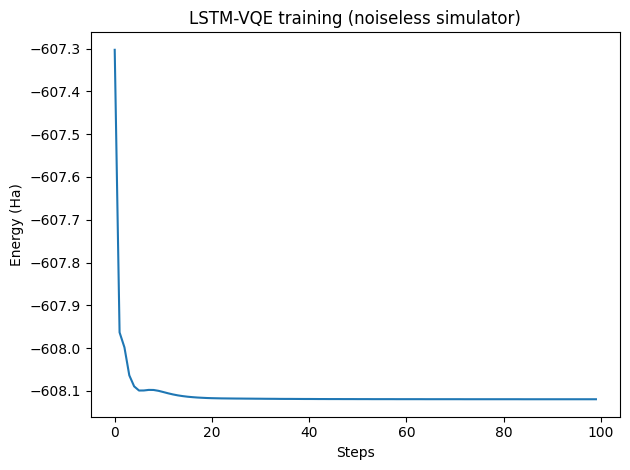

Ideal final energy: -608.1195068359 Ha


TypeError: Failed to convert a QubitOperator to a sparse matrix.

In [10]:
# ---------- Ideal LSTM-VQE training ----------
sim = Simulator('mqvector', circ.n_qubits)
grad_ops = sim.get_expectation_with_grad(ham, circ)

class TrainableLSTM(nn.Cell):
    def __init__(self):
        super(TrainableLSTM, self).__init__()
        n_params = len(circ.params_name)
        self.lstm = nn.LSTM(
            input_size=n_params,
            hidden_size=n_params,
            num_layers=1,
            has_bias=True,
            batch_first=False,
            bidirectional=False,
        )
        self.batch_size = 1
        self.num_layers = 1
        self.hidden_size = n_params
        self.hx = (
            Parameter(
                initializer(
                    'normal',
                    shape=[self.num_layers, self.batch_size, self.hidden_size],
                    dtype=ms.float32,
                ),
                name='h',
            ),
            Parameter(
                initializer(
                    'normal',
                    shape=[self.num_layers, self.batch_size, self.hidden_size],
                    dtype=ms.float32,
                ),
                name='c',
            ),
        )

    def construct(self, x):
        _, (hidden, _) = self.lstm(x, self.hx)
        return hidden

class All_Net(nn.Cell):
    def __init__(self, expectation_grad_ops, init_paras):
        super(All_Net, self).__init__()
        self.lstm = TrainableLSTM()
        self.qnn_ops = MQEncoderOnlyOps(expectation_grad_ops)
        self.init_paras = init_paras
        self.squeeze = ms.ops.Squeeze(0)

    def construct(self):
        self.init_paras = self.lstm(self.init_paras)
        params = self.squeeze(self.init_paras)
        return self.qnn_ops(params)

np.random.seed(1234)
paras = Tensor(
    np.random.random([1, 1, len(circ.params_name)]).astype(np.float32)
)

all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(), learning_rate=0.1)
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

energy_data = []
steps = 100

for step in range(steps):
    energy = train_net()
    energy_value = float(energy.asnumpy()[0, 0])
    energy_data.append(energy_value)

    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy_value:.10f} Ha")

plt.figure()
plt.plot(energy_data)
plt.title('LSTM-VQE training (noiseless simulator)')
plt.xlabel('Steps')
plt.ylabel('Energy (Ha)')
plt.tight_layout()
plt.savefig('lstm_vqe_ideal_training.png', dpi=300)
plt.show()

# 保存 LSTM 训练得到的线路参数，后续噪声实验使用同一组参数。
trained_params = np.asarray(all_net.init_paras.asnumpy()).reshape(-1)
if trained_params.size != len(circ.params_name):
    raise RuntimeError(
        f"Expected {len(circ.params_name)} ansatz parameters, "
        f"but got {trained_params.size}."
    )

print(f"Ideal final energy: {energy_data[-1]:.10f} Ha")

# ---------- Noisy finite-shot energy evaluation ----------

def group_qwc_terms(qubit_operator):
    """Greedy grouping of Pauli terms that share a measurement basis."""
    groups = []

    for term, coeff in qubit_operator.terms.items():
        if len(term) == 0:
            continue

        paulis = dict(term)
        placed = False

        for group in groups:
            basis = group['basis']
            if all(q not in basis or basis[q] == p for q, p in paulis.items()):
                basis.update(paulis)
                group['terms'].append((paulis, coeff))
                placed = True
                break

        if not placed:
            groups.append({
                'basis': dict(paulis),
                'terms': [(paulis, coeff)],
            })

    return groups

def append_noisy_gate(output_circuit, gate, p1, p2, gamma):
    """Append a gate followed by local gate-error and damping channels."""
    output_circuit += gate

    involved_qubits = list(gate.ctrl_qubits) + list(gate.obj_qubits)
    involved_qubits = list(dict.fromkeys(involved_qubits))

    if not involved_qubits:
        return

    # Approximate a two-qubit gate error by local noise on both participating
    # qubits. This is not a correlated two-qubit depolarizing channel.
    depolarizing_probability = p2 if len(involved_qubits) >= 2 else p1

    for qubit in involved_qubits:
        if depolarizing_probability > 0:
            output_circuit += DepolarizingChannel(
                depolarizing_probability
            ).on(qubit)
        if gamma > 0:
            output_circuit += AmplitudeDampingChannel(gamma).on(qubit)

def make_noisy_measurement_circuit(
    bound_circuit,
    basis,
    n_qubits,
    p1,
    p2,
    gamma,
):
    """Build a noisy ansatz, basis-change circuit, and computational readout."""
    noisy_circuit = Circuit()

    for gate in bound_circuit:
        append_noisy_gate(noisy_circuit, gate, p1, p2, gamma)

    for qubit, pauli in sorted(basis.items()):
        if pauli == 'X':
            append_noisy_gate(noisy_circuit, H.on(qubit), p1, p2, gamma)
        elif pauli == 'Y':
            # RZ(-pi/2) followed by H rotates the Y basis to the Z basis.
            append_noisy_gate(
                noisy_circuit,
                RZ(-np.pi / 2).on(qubit),
                p1,
                p2,
                gamma,
            )
            append_noisy_gate(noisy_circuit, H.on(qubit), p1, p2, gamma)

    for qubit in range(n_qubits):
        noisy_circuit += Measure(f'm{qubit}').on(qubit)

    return noisy_circuit

def parity_from_bitstring(bitstring, qubits):
    """Return +1 or -1 for the parity of the requested measured qubits."""
    bits = ''.join(ch for ch in str(bitstring) if ch in '01')

    if len(bits) != n_qubits:
        raise ValueError(
            f"Unexpected measurement key {bitstring!r}; "
            f"expected {n_qubits} bits."
        )

    # MindQuantum sampling keys follow the order of Measure gates above,
    # which is q0, q1, ..., q(n-1).
    parity = sum(int(bits[q]) for q in qubits) % 2
    return 1.0 if parity == 0 else -1.0

def estimate_noisy_energy(
    parameters,
    shots,
    p1=0.0,
    p2=0.0,
    gamma=0.0,
    readout_error=0.0,
):
    """Estimate Hamiltonian energy using noisy finite-shot measurements."""
    if shots <= 0:
        raise ValueError("shots must be positive.")

    if not 0 <= readout_error < 0.5:
        raise ValueError("readout_error must be in [0, 0.5).")

    parameter_dict = dict(zip(circ.params_name, parameters))
    bound_circuit = circ.apply_value(parameter_dict)
    groups = group_qwc_terms(hamiltonian_QubitOp)

    # The identity contribution does not need a measurement.
    energy = 0.0
    for term, coeff in hamiltonian_QubitOp.terms.items():
        if len(term) == 0:
            energy += float(np.real(coeff))

    noisy_simulator = Simulator('mqtrajectory', n_qubits)

    for group in groups:
        measurement_circuit = make_noisy_measurement_circuit(
            bound_circuit=bound_circuit,
            basis=group['basis'],
            n_qubits=n_qubits,
            p1=p1,
            p2=p2,
            gamma=gamma,
        )
        result = noisy_simulator.sampling(
            measurement_circuit,
            shots=shots,
        )
        counts = result.data

        for paulis, coeff in group['terms']:
            qubits = sorted(paulis)
            plus_count = 0
            minus_count = 0

            for bitstring, count in counts.items():
                parity = parity_from_bitstring(bitstring, qubits)
                if parity > 0:
                    plus_count += int(count)
                else:
                    minus_count += int(count)

            total_count = plus_count + minus_count
            if total_count == 0:
                raise RuntimeError("The sampler returned no measurement counts.")

            # Independent readout errors on the measured qubits induce an
            # effective parity-flip probability for this Pauli term.
            parity_flip_probability = (
                1.0 - (1.0 - 2.0 * readout_error) ** len(qubits)
            ) / 2.0

            observed_plus = np.random.binomial(
                plus_count,
                1.0 - parity_flip_probability,
            )
            observed_plus += np.random.binomial(
                minus_count,
                parity_flip_probability,
            )

            expectation = (
                2.0 * observed_plus - total_count
            ) / total_count

            energy += float(np.real(coeff)) * expectation

    return float(energy)

# Reference energy for reporting errors. This is the exact ground energy
# of the active-space qubit Hamiltonian, not an experimental measurement.
sparse_hamiltonian = get_sparse_operator(
    hamiltonian_QubitOp,
    n_qubits=n_qubits,
)
reference_energy = float(
    scipy.linalg.eigvalsh(sparse_hamiltonian.toarray())[0]
)
print(f"Active-space reference ground energy: {reference_energy:.10f} Ha")

# Each shot count is per QWC measurement group.
# These are illustrative hardware-inspired settings, not device calibration data.
noise_settings = [
    {
        'name': 'finite_shots_only',
        'p1': 0.0,
        'p2': 0.0,
        'gamma': 0.0,
        'readout_error': 0.0,
    },
    {
        'name': 'hardware_inspired',
        'p1': 1e-3,
        'p2': 1e-2,
        'gamma': 1e-3,
        'readout_error': 2e-2,
    },
]

shot_counts = [1024, 4096, 8192]
repeats = 10
results = []

for setting in noise_settings:
    for shots in shot_counts:
        estimates = []

        for repeat in range(repeats):
            # Seeds control NumPy-based randomness, including the simulated
            # classical readout flips. The simulator sampling RNG may be
            # managed separately by the installed MindQuantum version.
            np.random.seed(10000 + repeat + shots)

            estimate = estimate_noisy_energy(
                parameters=trained_params,
                shots=shots,
                p1=setting['p1'],
                p2=setting['p2'],
                gamma=setting['gamma'],
                readout_error=setting['readout_error'],
            )
            estimates.append(estimate)

        estimates = np.asarray(estimates)
        mean_energy = float(np.mean(estimates))
        std_energy = float(np.std(estimates, ddof=1))

        row = {
            'noise_model': setting['name'],
            'shots_per_group': shots,
            'repeats': repeats,
            'mean_energy_Ha': mean_energy,
            'std_energy_Ha': std_energy,
            'mean_abs_error_Ha': abs(mean_energy - reference_energy),
            'p1': setting['p1'],
            'p2': setting['p2'],
            'amplitude_damping_gamma': setting['gamma'],
            'readout_error': setting['readout_error'],
        }
        results.append(row)

        print(
            f"{setting['name']}, shots/group={shots}: "
            f"E={mean_energy:.10f} +/- {std_energy:.3e} Ha, "
            f"|E-Eref|={row['mean_abs_error_Ha']:.3e} Ha"
        )

with open('lstm_vqe_noise_results.csv', 'w', newline='') as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

plt.figure()
for setting in noise_settings:
    selected = [
        row for row in results
        if row['noise_model'] == setting['name']
    ]
    xs = [row['shots_per_group'] for row in selected]
    ys = [row['mean_abs_error_Ha'] for row in selected]
    errors = [row['std_energy_Ha'] for row in selected]

    plt.errorbar(
        xs,
        ys,
        yerr=errors,
        marker='o',
        capsize=3,
        label=setting['name'],
    )

plt.xscale('log', base=2)
plt.xlabel('Shots per QWC measurement group')
plt.ylabel('Absolute energy error (Ha)')
plt.legend()
plt.tight_layout()
#plt.savefig('lstm_vqe_noise_results.png', dpi=300)
plt.show()


[WARNING] ME(769280:124093908422656,MainProcess):2026-09-30-18:13:24.564.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


[['Zr', [np.float64(1.2397611467218508), np.float64(0.22042881), np.float64(1.102028681533527)]], ['O', [np.float64(4.657048362037544), np.float64(4.36031376), np.float64(0.8211243583071115)]], ['O', [np.float64(1.4584165528787967), np.float64(3.8836934000000003), np.float64(5.145324267709785)]]]
Monoclinic ZrO2 - Hartree-Fock energy: -608.1196082141597 Hartree.
Monoclinic ZrO2 - CCSD energy: -608.3663660904948 Hartree.
Step 0: Energy = -607.3027343750 Ha
Step 10: Energy = -608.1026611328 Ha
Step 20: Energy = -608.1170043945 Ha
Step 30: Energy = -608.1182861328 Ha
Step 40: Energy = -608.1188964844 Ha
Step 50: Energy = -608.1192016602 Ha
Step 60: Energy = -608.1193237305 Ha
Step 70: Energy = -608.1193847656 Ha
Step 80: Energy = -608.1194458008 Ha
Step 90: Energy = -608.1195068359 Ha


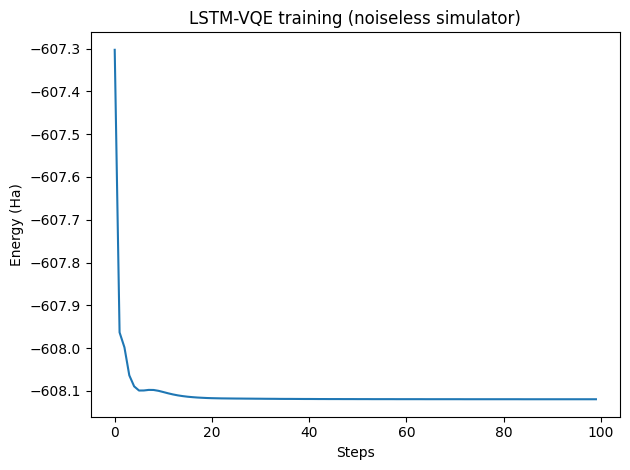

Ideal final energy: -608.1195068359 Ha
Active-space reference ground energy: -609.6064471621 Ha


/tmp/ipykernel_769280/1281431203.py:379: DeprecationWarning: ParameterResolver.__float__ returned non-float (type numpy.float64).  The ability to return an instance of a strict subclass of float is deprecated, and may be removed in a future version of Python.
  return float(float(val))


finite_shots_only, shots/group=1024: E=-605.6625065047 +/- 1.450e-03 Ha, |E-Eref|=3.944e+00 Ha


In [ ]:
import numpy as np
import mindspore as ms
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer
import matplotlib.pyplot as plt

from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X, H, RZ, Measure, DepolarizingChannel, AmplitudeDampingChannel
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian, FermionOperator, down_index, up_index
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package
from mindquantum.algorithm.nisq.chem.transform import Transform as ChemTransform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator

import scipy
import scipy.linalg
from scipy.sparse.linalg import eigsh

import itertools
from collections import OrderedDict
import random
import csv

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")


def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    n_single_amplitudes = n_occupied * n_virtual
    spin_index_functions = [up_index, down_index]

    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])

    out.extend(out_tmp)
    out_tmp = []

    for i, ((p, q), (r, s)) in enumerate(
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)

            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])

    return out, params


def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    try:
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(
        mol, threshold,
        n_qubits=2 * (active_space_stop - active_space_start),
        n_electrons=mol.n_electrons - 2 * active_space_start
    )
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(
        list(range(active_space_start)),
        active_indices=range(active_space_start, active_space_stop)
    )
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return (
        uccsd_circuit, initial_amplitudes, parameters_name,
        qubit_hamiltonian,
        2 * (active_space_stop - active_space_start),
        mol.n_electrons - 2 * active_space_start
    )


def get_mol(phase=1):
    if phase == 1:
        a, b, c = 5.15, 5.23, 5.33
        beta = 99.44 * np.pi / 180
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        a = b = 3.60
        c = 5.23
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [('Zr', [0, 0, 0]), ('O', [0, 0.5, 0.301775])]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        a, c = 5.31, 3.2
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a / 2, a * np.sqrt(3) / 2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [('Zr', [0, 0, 0]), ('O', [1 / 3, 2 / 3, 0.25])]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    geometry = []
    for element, frac_coords in atoms:
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1

    molecule = MolecularData(geometry, basis, multiplicity, description=description)

    try:
        molecule.load()
    except Exception:
        molecule = run_pyscf(molecule, run_scf=1, run_ccsd=1)
        molecule.save()
        molecule.load()
        print(molecule.filename.split('/')[-1])

    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
    return molecule


# ===================== 分子与 UCCSD 构建 =====================
ZrO2d = get_mol(1)
ansatz_circuit, init_amplitudes, ansatz_parameter_names, \
    hamiltonian_QubitOp, n_qubits, n_electrons = generate_uccsd(
        ZrO2d, threshold=-1, active_space_start=27, active_space_stop=33
    )

hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
ham = Hamiltonian(hamiltonian_QubitOp)
circ = hartreefock_wfn_circuit + ansatz_circuit.as_encoder()
sim = Simulator('mqvector', circ.n_qubits)
grad_ops = sim.get_expectation_with_grad(ham, circ)


# ===================== LSTM-VQE 网络定义 =====================
class TrainableLSTM(nn.Cell):
    def __init__(self):
        super(TrainableLSTM, self).__init__()
        n_params = len(circ.params_name)
        self.lstm = nn.LSTM(
            input_size=n_params, hidden_size=n_params, num_layers=1,
            has_bias=True, batch_first=False, bidirectional=False,
        )
        self.batch_size = 1
        self.num_layers = 1
        self.hidden_size = n_params
        self.hx = (
            Parameter(initializer('normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='h'),
            Parameter(initializer('normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='c'),
        )

    def construct(self, x):
        _, (hidden, _) = self.lstm(x, self.hx)
        return hidden


class All_Net(nn.Cell):
    def __init__(self, expectation_grad_ops, init_paras):
        super(All_Net, self).__init__()
        self.lstm = TrainableLSTM()
        self.qnn_ops = MQEncoderOnlyOps(expectation_grad_ops)
        self.init_paras = init_paras
        self.squeeze = ms.ops.Squeeze(0)

    def construct(self):
        self.init_paras = self.lstm(self.init_paras)
        params = self.squeeze(self.init_paras)
        return self.qnn_ops(params)


# ===================== Ideal LSTM-VQE Training =====================
np.random.seed(1234)
paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))

all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(), learning_rate=0.1)
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_value = float(energy.asnumpy()[0, 0])
    energy_data.append(energy_value)
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy_value:.10f} Ha")

plt.figure()
plt.plot(energy_data)
plt.title('LSTM-VQE training (noiseless simulator)')
plt.xlabel('Steps')
plt.ylabel('Energy (Ha)')
plt.tight_layout()
plt.savefig('lstm_vqe_ideal_training.png', dpi=300)
plt.show()

trained_params = np.asarray(all_net.init_paras.asnumpy()).reshape(-1)
if trained_params.size != len(circ.params_name):
    raise RuntimeError(
        f"Expected {len(circ.params_name)} ansatz parameters, but got {trained_params.size}."
    )
print(f"Ideal final energy: {energy_data[-1]:.10f} Ha")


# ===================== Noisy Finite-Shot Energy Evaluation =====================

def group_qwc_terms(qubit_operator):
    """Greedy grouping of Pauli terms that share a measurement basis."""
    groups = []
    for term, coeff in qubit_operator.terms.items():
        if len(term) == 0:
            continue
        paulis = dict(term)
        placed = False
        for group in groups:
            basis = group['basis']
            if all(q not in basis or basis[q] == p for q, p in paulis.items()):
                basis.update(paulis)
                group['terms'].append((paulis, coeff))
                placed = True
                break
        if not placed:
            groups.append({'basis': dict(paulis), 'terms': [(paulis, coeff)]})
    return groups


def append_noisy_gate(output_circuit, gate, p1, p2, gamma):
    """Append a gate followed by local gate-error and damping channels."""
    output_circuit += gate
    involved_qubits = list(gate.ctrl_qubits) + list(gate.obj_qubits)
    involved_qubits = list(dict.fromkeys(involved_qubits))
    if not involved_qubits:
        return
    depolarizing_probability = p2 if len(involved_qubits) >= 2 else p1
    for qubit in involved_qubits:
        if depolarizing_probability > 0:
            output_circuit += DepolarizingChannel(depolarizing_probability).on(qubit)
        if gamma > 0:
            output_circuit += AmplitudeDampingChannel(gamma).on(qubit)


def make_noisy_measurement_circuit(bound_circuit, basis, n_qubits_val, p1, p2, gamma):
    """Build a noisy ansatz, basis-change circuit, and computational readout."""
    noisy_circuit = Circuit()
    for gate in bound_circuit:
        append_noisy_gate(noisy_circuit, gate, p1, p2, gamma)
    for qubit, pauli in sorted(basis.items()):
        if pauli == 'X':
            append_noisy_gate(noisy_circuit, H.on(qubit), p1, p2, gamma)
        elif pauli == 'Y':
            append_noisy_gate(noisy_circuit, RZ(-np.pi / 2).on(qubit), p1, p2, gamma)
            append_noisy_gate(noisy_circuit, H.on(qubit), p1, p2, gamma)
    for qubit in range(n_qubits_val):
        noisy_circuit += Measure(f'm{qubit}').on(qubit)
    return noisy_circuit


def parity_from_bitstring(bitstring, qubits, total_qubits):
    """Return +1 or -1 for the parity of the requested measured qubits."""
    bits = ''.join(ch for ch in str(bitstring) if ch in '01')
    if len(bits) != total_qubits:
        raise ValueError(f"Unexpected measurement key {bitstring!r}; expected {total_qubits} bits.")
    parity = sum(int(bits[q]) for q in qubits) % 2
    return 1.0 if parity == 0 else -1.0


def _safe_float(coeff):
    """安全地将 MindQuantum 系数转换为 Python float，避免 ParameterResolver DeprecationWarning。"""
    val = np.real(coeff)
    # ParameterResolver / numpy.float64 → Python float
    return float(float(val))


def estimate_noisy_energy(parameters, shots, p1=0.0, p2=0.0, gamma=0.0, readout_error=0.0):
    """Estimate Hamiltonian energy using noisy finite-shot measurements.

    修复：
    1. 将 'mqtrajectory' 替换为 'mqvector'（mqtrajectory 在部分安装中不可用）。
       mqvector 在含噪声通道时自动切换为密度矩阵模拟。
    2. 系数转换使用 _safe_float 消除 DeprecationWarning。
    """
    if shots <= 0:
        raise ValueError("shots must be positive.")
    if not 0 <= readout_error < 0.5:
        raise ValueError("readout_error must be in [0, 0.5).")

    parameter_dict = dict(zip(circ.params_name, parameters))
    bound_circuit = circ.apply_value(parameter_dict)
    groups = group_qwc_terms(hamiltonian_QubitOp)

    # Identity contribution
    energy = 0.0
    for term, coeff in hamiltonian_QubitOp.terms.items():
        if len(term) == 0:
            energy += _safe_float(coeff)

    # 【关键修复】使用 mqvector 替代 mqtrajectory
    # mqvector 在检测到噪声通道时会自动使用密度矩阵模式进行采样
    noisy_simulator = Simulator('mqvector', n_qubits)

    for group in groups:
        measurement_circuit = make_noisy_measurement_circuit(
            bound_circuit=bound_circuit,
            basis=group['basis'],
            n_qubits_val=n_qubits,
            p1=p1, p2=p2, gamma=gamma,
        )
        result = noisy_simulator.sampling(measurement_circuit, shots=shots)
        counts = result.data

        for paulis, coeff in group['terms']:
            qubits = sorted(paulis)
            plus_count = 0
            minus_count = 0

            for bitstring, count in counts.items():
                parity = parity_from_bitstring(bitstring, qubits, n_qubits)
                if parity > 0:
                    plus_count += int(count)
                else:
                    minus_count += int(count)

            total_count = plus_count + minus_count
            if total_count == 0:
                raise RuntimeError("The sampler returned no measurement counts.")

            parity_flip_probability = (
                1.0 - (1.0 - 2.0 * readout_error) ** len(qubits)
            ) / 2.0

            observed_plus = np.random.binomial(plus_count, 1.0 - parity_flip_probability)
            observed_plus += np.random.binomial(minus_count, parity_flip_probability)

            expectation = (2.0 * observed_plus - total_count) / total_count
            energy += _safe_float(coeff) * expectation

    return float(energy)


# ===================== Reference Energy =====================
sparse_hamiltonian = ham.sparse_matrix
if sparse_hamiltonian.shape[0] > 2048:
    reference_energy = float(eigsh(sparse_hamiltonian, k=1, which='SA')[0][0])
else:
    reference_energy = float(scipy.linalg.eigvalsh(sparse_hamiltonian.toarray())[0])
print(f"Active-space reference ground energy: {reference_energy:.10f} Ha")


# ===================== Noise Experiments =====================
noise_settings = [
    {'name': 'finite_shots_only', 'p1': 0.0, 'p2': 0.0, 'gamma': 0.0, 'readout_error': 0.0},
    {'name': 'hardware_inspired', 'p1': 1e-3, 'p2': 1e-2, 'gamma': 1e-3, 'readout_error': 2e-2},
]

shot_counts = [1024, 4096, 8192]
repeats = 10
results = []

for setting in noise_settings:
    for shots in shot_counts:
        estimates = []
        for repeat in range(repeats):
            np.random.seed(10000 + repeat + shots)
            estimate = estimate_noisy_energy(
                parameters=trained_params,
                shots=shots,
                p1=setting['p1'],
                p2=setting['p2'],
                gamma=setting['gamma'],
                readout_error=setting['readout_error'],
            )
            estimates.append(estimate)

        estimates = np.asarray(estimates)
        mean_energy = float(np.mean(estimates))
        std_energy = float(np.std(estimates, ddof=1))

        row = {
            'noise_model': setting['name'],
            'shots_per_group': shots,
            'repeats': repeats,
            'mean_energy_Ha': mean_energy,
            'std_energy_Ha': std_energy,
            'mean_abs_error_Ha': abs(mean_energy - reference_energy),
            'p1': setting['p1'],
            'p2': setting['p2'],
            'amplitude_damping_gamma': setting['gamma'],
            'readout_error': setting['readout_error'],
        }
        results.append(row)
        print(
            f"{setting['name']}, shots/group={shots}: "
            f"E={mean_energy:.10f} +/- {std_energy:.3e} Ha, "
            f"|E-Eref|={row['mean_abs_error_Ha']:.3e} Ha"
        )

with open('lstm_vqe_noise_results.csv', 'w', newline='') as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

plt.figure()
for setting in noise_settings:
    selected = [row for row in results if row['noise_model'] == setting['name']]
    xs = [row['shots_per_group'] for row in selected]
    ys = [row['mean_abs_error_Ha'] for row in selected]
    errors = [row['std_energy_Ha'] for row in selected]
    plt.errorbar(xs, ys, yerr=errors, marker='o', capsize=3, label=setting['name'])

plt.xscale('log', base=2)
plt.xlabel('Shots per QWC measurement group')
plt.ylabel('Absolute energy error (Ha)')
plt.legend()
plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import mindspore as ms
from mindspore import nn, Parameter, Tensor
from mindspore.common.initializer import initializer

from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf

from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian, QubitOperator
from mindquantum.simulator import Simulator
from mindquantum.framework import MQEncoderOnlyLayer

# 保留你原来的两个自定义函数定义，放在本代码之前：
#   _para_uccsd_singlet_generator(...)
#   generate_uccsd(..., active_space_start=..., active_space_stop=...)
#
# 这两个函数负责根据分子数据生成 active-space UCCSD ansatz 和哈密顿量。

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

def get_mol(phase=1):
    """构造晶体结构并运行或读取 PySCF 分子计算。"""
    if phase == 1:
        a = 5.15
        b = 5.23
        c = 5.33
        beta = 99.44 * np.pi / 180

        a_vec = np.array([a, 0.0, 0.0])
        b_vec = np.array([0.0, b, 0.0])
        c_vec = np.array([c * np.cos(beta), 0.0, c * np.sin(beta)])

        atoms = [
            ("Zr", [0.276309, 0.042147, 0.209598]),
            ("O", [0.930791, 0.833712, 0.156172]),
            ("O", [0.449303, 0.742580, 0.978604]),
        ]
        description = "Monoclinic ZrO2"

    elif phase == 2:
        a = b = 3.60
        c = 5.23

        a_vec = np.array([a, 0.0, 0.0])
        b_vec = np.array([0.0, b, 0.0])
        c_vec = np.array([0.0, 0.0, c])

        atoms = [
            ("Zr", [0.0, 0.0, 0.0]),
            ("O", [0.0, 0.5, 0.301775]),
        ]
        description = "Tetragonal ZrO2"

    elif phase == 3:
        a = 5.31
        c = 3.2

        a_vec = np.array([a, 0.0, 0.0])
        b_vec = np.array([-a / 2, a * np.sqrt(3) / 2, 0.0])
        c_vec = np.array([0.0, 0.0, c])

        atoms = [
            ("Zr", [0.0, 0.0, 0.0]),
            ("O", [1 / 3, 2 / 3, 0.25]),
        ]
        description = "Hexagonal ZrO"

    else:
        raise ValueError("phase 必须为 1、2 或 3。")

    geometry = []
    for element, frac_coords in atoms:
        cart_coords = (
            frac_coords[0] * a_vec
            + frac_coords[1] * b_vec
            + frac_coords[2] * c_vec
        )
        geometry.append([element, cart_coords.tolist()])

    print("Molecular geometry:", geometry)

    molecule = MolecularData(
        geometry=geometry,
        basis="gth-dzvp-molopt-sr",
        multiplicity=1,
        description=description,
    )

    try:
        molecule.load()
    except (OSError, FileNotFoundError, KeyError):
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()

    print(f"{description} HF energy: {molecule.hf_energy} Hartree")
    print(f"{description} CCSD energy: {molecule.ccsd_energy} Hartree")
    return molecule

class TrainableLSTM(nn.Cell):
    """LSTM 将上一轮参数向量映射为当前轮量子线路参数。"""

    def __init__(self, n_params):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_params,
            hidden_size=n_params,
            num_layers=1,
            has_bias=True,
            batch_first=False,
            bidirectional=False,
        )

        self.hx = (
            Parameter(
                initializer(
                    "normal",
                    shape=[1, 1, n_params],
                    dtype=ms.float32,
                ),
                name="lstm_hidden",
            ),
            Parameter(
                initializer(
                    "normal",
                    shape=[1, 1, n_params],
                    dtype=ms.float32,
                ),
                name="lstm_cell",
            ),
        )

    def construct(self, x):
        output, _ = self.lstm(x, self.hx)
        return output

class AllNet(nn.Cell):
    """LSTM 参数生成器与 MindQuantum encoder-only 层。"""

    def __init__(self, grad_ops, n_params):
        super().__init__()
        self.lstm = TrainableLSTM(n_params)
        self.qnn_ops = MQEncoderOnlyLayer(grad_ops)
        self.squeeze_sequence = ms.ops.Squeeze(0)

    def construct(self, x):
        # LSTM 输出形状为 [sequence, batch, n_params]。
        encoded_params = self.lstm(x)
        # MindQuantum encoder-only 层的输入形状为 [batch, n_params]。
        encoded_params = self.squeeze_sequence(encoded_params)
        return self.qnn_ops(encoded_params)

def sample_shot_energies(
    qubit_hamiltonian,
    circuit,
    parameter_values,
    n_qubits,
    shots,
    repeats=100,
    seed=1,
):
    """
    逐 Pauli 项进行有限 shot 采样。

    每个 Pauli 项独立测量 shots 次，因此总 shot 数约为：
    shots × 非恒等 Pauli 项数。
    """
    rng = np.random.default_rng(seed)
    estimates = np.zeros(repeats, dtype=np.float64)

    param_dict = dict(zip(circuit.params_name, parameter_values))

    # 准备带有最终线路参数的量子态。
    sim = Simulator("mqvector", n_qubits)
    sim.apply_circuit(circuit, pr=param_dict)

    for term, coeff in qubit_hamiltonian.terms.items():
        coeff = complex(coeff)
        if abs(coeff.imag) > 1e-10:
            raise ValueError(f"哈密顿量系数不是实数：{coeff}")

        coeff = coeff.real

        # 恒等项是常数，不需要采样。
        if len(term) == 0:
            estimates += coeff
            continue

        pauli_hamiltonian = Hamiltonian(QubitOperator(term, 1.0))
        expectation = sim.get_expectation(pauli_hamiltonian)
        expectation = float(np.asarray(expectation).real.reshape(-1)[0])
        expectation = np.clip(expectation, -1.0, 1.0)

        # Pauli 测量结果为 +1 或 -1。
        probability_positive = (1.0 + expectation) / 2.0
        n_positive = rng.binomial(
            shots,
            probability_positive,
            size=repeats,
        )
        sampled_expectation = 2.0 * n_positive / shots - 1.0
        estimates += coeff * sampled_expectation

    return estimates

# ----------------------------------------------------------------------
# 构造分子、active-space UCCSD 线路和哈密顿量
# ----------------------------------------------------------------------

molecule = get_mol(phase=1)

active_space_start = 27
active_space_stop = 33

(
    ansatz_circuit,
    init_amplitudes,
    ansatz_parameter_names,
    hamiltonian_qubit_op,
    n_qubits,
    n_electrons,
) = generate_uccsd(
    molecule,
    threshold=-1,
    active_space_start=active_space_start,
    active_space_stop=active_space_stop,
)

if n_electrons > n_qubits:
    raise ValueError(
        f"active space 中电子数 {n_electrons} 大于量子比特数 {n_qubits}。"
        "请检查 active_space_start / active_space_stop 和电子数定义。"
    )

hartree_fock_circuit = Circuit([X.on(i) for i in range(n_electrons)])

# 将 UCCSD 参数标记为 encoder 参数，由 LSTM 输出。
circuit = hartree_fock_circuit + ansatz_circuit.as_encoder()
hamiltonian = Hamiltonian(hamiltonian_qubit_op)

if len(circuit.params_name) != len(ansatz_parameter_names):
    raise ValueError(
        "线路参数数量与 UCCSD 参数名称数量不一致："
        f"{len(circuit.params_name)} != {len(ansatz_parameter_names)}"
    )

n_params = len(circuit.params_name)
if n_params == 0:
    raise ValueError("线路没有可训练参数，请检查 UCCSD ansatz 生成结果。")

print(f"Number of qubits: {n_qubits}")
print(f"Number of electrons: {n_electrons}")
print(f"Number of circuit parameters: {n_params}")

simulator = Simulator("mqvector", circuit.n_qubits)
grad_ops = simulator.get_expectation_with_grad(hamiltonian, circuit)

# ----------------------------------------------------------------------
# LSTM-VQE 训练
# ----------------------------------------------------------------------

all_net = AllNet(grad_ops, n_params)
optimizer = nn.Adam(
    all_net.trainable_params(),
    learning_rate=0.1,
)
train_net = nn.TrainOneStepCell(all_net, optimizer)
train_net.set_train()

# LSTM 输入形状：[sequence=1, batch=1, parameter_count]。
current_input = Tensor(
    np.random.uniform(-0.1, 0.1, size=(1, 1, n_params)).astype(np.float32)
)

energy_data = []
steps = 100

for step in range(steps):
    energy = train_net(current_input)
    energy_value = float(np.asarray(energy.asnumpy()).reshape(-1)[0])
    energy_data.append(energy_value)

    if step % 10 == 0:
        print(f"Step {step}: energy = {energy_value:.10f} Hartree")

    # 将本轮 LSTM 输出作为下一轮输入。
    current_input = all_net.lstm(current_input)

plt.figure()
plt.plot(energy_data)
plt.xlabel("Steps")
plt.ylabel("Energy (Hartree)")
plt.title("LSTM-VQE Training for Monoclinic ZrO2")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 最终参数的解析能量与 finite-shot 能量估计
# ----------------------------------------------------------------------

# 用训练后的 LSTM 输出生成最终线路参数。
final_parameter_tensor = all_net.lstm(current_input)
final_parameters = np.asarray(final_parameter_tensor.asnumpy()).reshape(-1)

if len(final_parameters) != len(circuit.params_name):
    raise ValueError(
        f"最终参数数量不匹配：{len(final_parameters)} != {len(circuit.params_name)}"
    )

final_param_dict = dict(zip(circuit.params_name, final_parameters))

# 解析期望值，作为 shot-noise 对照。
exact_simulator = Simulator("mqvector", circuit.n_qubits)
exact_energy = exact_simulator.get_expectation(
    hamiltonian,
    circuit,
    pr=final_param_dict,
)
exact_energy = float(np.asarray(exact_energy).real.reshape(-1)[0])

print(f"\nExact final energy: {exact_energy:.10f} Hartree")

shot_counts = [100, 500, 1000, 5000]
repeats = 100
shot_means = []
shot_stds = []

for shots in shot_counts:
    samples = sample_shot_energies(
        qubit_hamiltonian=hamiltonian_qubit_op,
        circuit=circuit,
        parameter_values=final_parameters,
        n_qubits=circuit.n_qubits,
        shots=shots,
        repeats=repeats,
        seed=shots,
    )

    mean_energy = float(samples.mean())
    std_energy = float(samples.std(ddof=1))
    shot_means.append(mean_energy)
    shot_stds.append(std_energy)

    print(
        f"shots={shots:5d}, "
        f"mean={mean_energy:.10f} Hartree, "
        f"std={std_energy:.10f} Hartree, "
        f"exact={exact_energy:.10f} Hartree"
    )

plt.figure()
plt.errorbar(
    shot_counts,
    shot_means,
    yerr=shot_stds,
    fmt="o-",
    capsize=4,
    label="Finite-shot estimate (mean +/- std)",
)
plt.axhline(
    exact_energy,
    color="black",
    linestyle="--",
    label="Exact expectation",
)
plt.xscale("log")
plt.xlabel("Shots per Pauli term")
plt.ylabel("Energy (Hartree)")
plt.title("Finite-shot Energy Estimation")
plt.legend()
plt.tight_layout()
plt.show()


ImportError: cannot import 'MQEncoderOnlyLayer' from 'mindquantum'. 'MQEncoderOnlyLayer' does not exist in mindquantum.